# JagaDia - 04. Safe Route Recommender System

**Mata Kuliah:** Machine Learning (COMP657701)
**Sesi Acuan:** Session 13-14 (Recommender System: Content-Based Recommendation & Utility Model)

---

### Konsep Teori Recommender System (Session 13-14):
1. **Formal Model (Slide 15):**
   - $X = \text{Set of Users}$ (Pengguna dengan preferensi keamanan $\alpha$).
   - $S = \text{Set of Items}$ (Kandidat rute perjalanan antara titik asal dan tujuan).
   - Fungsi Utilitas / Biaya: $u : X \times S \to \mathbb{R}$.
2. **Content-Based Filtering (Slide 26-30):**
   - **Item Profile (Route Features):** Vektor fitur setiap rute (jarak, durasi, probabilitas risiko rata-rata, risiko puncak, indeks pencahayaan).
   - **User Profile (Preference Weights):** Parameter sensitivitas keamanan pengguna $\alpha$.
3. **Multi-Criteria Safety Cost Scoring:**
   $$\text{Total Cost}(r) = \text{Jarak Tempuh (meter)} + \alpha \times \sum_{i} (\text{Probabilitas Risiko}_i \times \Delta d_i)$$
   - $\alpha = 0.2$ (*Prefer Cepat*): Memprioritaskan jarak tempuh dan waktu tersingkat.
   - $\alpha = 1.0$ (*Seimbang*): Menyeimbangkan antara jarak tempuh dan keamanan.
   - $\alpha = 3.0$ (*Sangat Aman - Persona Utama JagaDia*): Sangat memprioritaskan keamanan (menghindari zona rawan tawuran/kriminalitas malam hari meskipun harus sedikit memutar).

In [1]:
import sys
from pathlib import Path

# Tambahkan direktori root ML ke path modul
ml_root = Path.cwd().parent
if str(ml_root) not in sys.path:
    sys.path.append(str(ml_root))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from src.route_recommender import (
    load_best_classifier,
    create_sample_jakarta_candidate_routes,
    evaluate_route_waypoints,
    score_and_rank_routes,
    SAFETY_PRESETS,
)

# Muat model klasifikasi terbaik hasil Tahap 2
classifier_pipeline = load_best_classifier()
print("Setup berhasil! Model klasifikasi Tahap 2 siap digunakan untuk evaluasi rute.")

Setup berhasil! Model klasifikasi Tahap 2 siap digunakan untuk evaluasi rute.


## 1. Definisi Item Profile: Kandidat Rute Perjalanan (Candidate Routes)
Sebagai studi kasus nyata di Jakarta Pusat, kita mensimulasikan perjalanan dari **Stasiun Pasar Senen** menuju kawasan **Cikini / Menteng** pada malam hari (Pukul 21.00 WIB, akhir pekan):

- **Rute 1 (Jalur Pintas Gang Johar Baru):** Jarak paling pendek (2.4 km), namun melewati gang sempit dengan penerangan minim dan menembus cluster hotspot tawuran Galur (DBSCAN Cluster #1).
- **Rute 2 (Jalur Protokol Salemba Raya):** Jarak sedikit lebih panjang (2.9 km), namun melalui jalan arteri protokol yang lebar, penerangan terang, dan melintasi kantor Polres Jakarta Pusat.
- **Rute 3 (Jalur Kolektor Kwitang):** Jarak menengah (2.6 km), melewati jalan kolektor dengan karakteristik sedang.

In [2]:
candidate_routes = create_sample_jakarta_candidate_routes()

print(f"Tersedia {len(candidate_routes)} kandidat rute perjalanan:")
for r in candidate_routes:
    print(f"- [{r['route_id']}] {r['name']} | Tipe: {r['road_type']} | Penerangan: {r['street_light_density']}")

Tersedia 3 kandidat rute perjalanan:
- [R01_SHORTCUT] Jalur Pintas Johar Baru (Gang & Lokal) | Tipe: gang | Penerangan: 0.2
- [R02_ARTERI_SAFE] Jalur Protokol Kramat - Salemba (Arteri Terang) | Tipe: arteri | Penerangan: 0.85
- [R03_KOLEKTOR_MID] Jalur Kolektor Kwitang (Kolektor) | Tipe: kolektor | Penerangan: 0.6


## 2. Evaluasi Titik-Titik Waypoint Rute Menggunakan Model ML (Tahap 2)
Setiap titik koordinat sepanjang jalur dievaluasi probabilitas risikonya $P(\text{Rawan})$ menggunakan `classifier_pipeline.predict_proba()`.

In [3]:
TRAVEL_HOUR = 21       # Pukul 21.00 malam
DAY_OF_WEEK = 5        # Malam Minggu (Sabtu)

print("=== CONTOH EVALUASI WAYPOINT RUTE 1 (JALUR PINTAS JOHAR BARU) ===")
sample_eval_df = evaluate_route_waypoints(
    candidate_routes[0]["waypoints"],
    classifier_pipeline,
    hour=TRAVEL_HOUR,
    day_of_week=DAY_OF_WEEK,
    road_type=candidate_routes[0]["road_type"],
    street_light_density=candidate_routes[0]["street_light_density"],
)

display(sample_eval_df[["latitude", "longitude", "segment_length_m", "dist_to_hotspot_m", "risk_probability"]])

=== CONTOH EVALUASI WAYPOINT RUTE 1 (JALUR PINTAS JOHAR BARU) ===


,latitude,longitude,segment_length_m,dist_to_hotspot_m,risk_probability
0,-6.1754,106.8451,0.000000,227.698078,0.9992
1,-6.1752,106.8520,763.117117,987.001169,0.9992
2,-6.1751,106.8651,1448.244303,12.470449,0.9993
3,-6.1820,106.8630,801.598329,792.807463,0.9992
4,-6.1880,106.8550,1107.811267,428.992592,0.9990
5,-6.1950,106.8420,1634.354317,940.694230,0.9984


## 3. Eksperimen Pengaruh Parameter Preferensi Pengguna ($\alpha$)
Menguji bagaimana sistem rekomendasi mengubah peringkat rute (*ranking*) berdasarkan preferensi pengguna (*User Profile*).

In [4]:
personas = [
    ("Prefer Cepat (Fastest)", SAFETY_PRESETS["prefer_cepat"]),
    ("Seimbang (Balanced)", SAFETY_PRESETS["seimbang"]),
    ("Sangat Aman (Safest - Target SDGs 5/11)", SAFETY_PRESETS["sangat_aman"]),
]

for label, alpha_val in personas:
    df_rank, _ = score_and_rank_routes(
        candidate_routes,
        classifier_pipeline,
        alpha=alpha_val,
        hour=TRAVEL_HOUR,
        day_of_week=DAY_OF_WEEK,
    )
    
    print("=" * 65)
    print(f"PROFIL PENGGUNA: {label} (Alpha = {alpha_val})")
    print("=" * 65)
    cols = ["recommendation_rank", "route_name", "distance_km", "duration_min", "mean_risk_prob", "safety_score", "total_cost"]
    display(df_rank[cols])
    print(f"-> Rute Terbaik yang Direkomendasikan: {df_rank.iloc[0]['route_name']}\n")

PROFIL PENGGUNA: Prefer Cepat (Fastest) (Alpha = 0.2)


,recommendation_rank,route_name,distance_km,duration_min,mean_risk_prob,safety_score,total_cost
0,1,Jalur Protokol Kramat - Salemba (Arteri Terang),2.50,5.6,0.004,99.6,2504.5
1,2,Jalur Kolektor Kwitang (Kolektor),2.72,6.0,0.341,65.9,3090.6
2,3,Jalur Pintas Johar Baru (Gang & Lokal),5.76,12.8,0.999,0.1,8054.8


-> Rute Terbaik yang Direkomendasikan: Jalur Protokol Kramat - Salemba (Arteri Terang)

PROFIL PENGGUNA: Seimbang (Balanced) (Alpha = 1.0)


,recommendation_rank,route_name,distance_km,duration_min,mean_risk_prob,safety_score,total_cost
0,1,Jalur Protokol Kramat - Salemba (Arteri Terang),2.50,5.6,0.004,99.6,2518.8
1,2,Jalur Kolektor Kwitang (Kolektor),2.72,6.0,0.341,65.9,4572.8
2,3,Jalur Pintas Johar Baru (Gang & Lokal),5.76,12.8,0.999,0.1,17253.4


-> Rute Terbaik yang Direkomendasikan: Jalur Protokol Kramat - Salemba (Arteri Terang)

PROFIL PENGGUNA: Sangat Aman (Safest - Target SDGs 5/11) (Alpha = 3.0)


,recommendation_rank,route_name,distance_km,duration_min,mean_risk_prob,safety_score,total_cost
0,1,Jalur Protokol Kramat - Salemba (Arteri Terang),2.50,5.6,0.004,99.6,2554.7
1,2,Jalur Kolektor Kwitang (Kolektor),2.72,6.0,0.341,65.9,8278.6
2,3,Jalur Pintas Johar Baru (Gang & Lokal),5.76,12.8,0.999,0.1,40249.9


-> Rute Terbaik yang Direkomendasikan: Jalur Protokol Kramat - Salemba (Arteri Terang)



## 4. Visualisasi Komparasi Fitur & Total Cost antar Rute

C:\Users\evanh\AppData\Local\Temp\ipykernel_36768\2733382372.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=df_final_rank, x="distance_km", y="route_name", palette="Blues_r")
C:\Users\evanh\AppData\Local\Temp\ipykernel_36768\2733382372.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=df_final_rank, x="mean_risk_prob", y="route_name", palette="Reds_r")
C:\Users\evanh\AppData\Local\Temp\ipykernel_36768\2733382372.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2], data=df_final_rank, x="

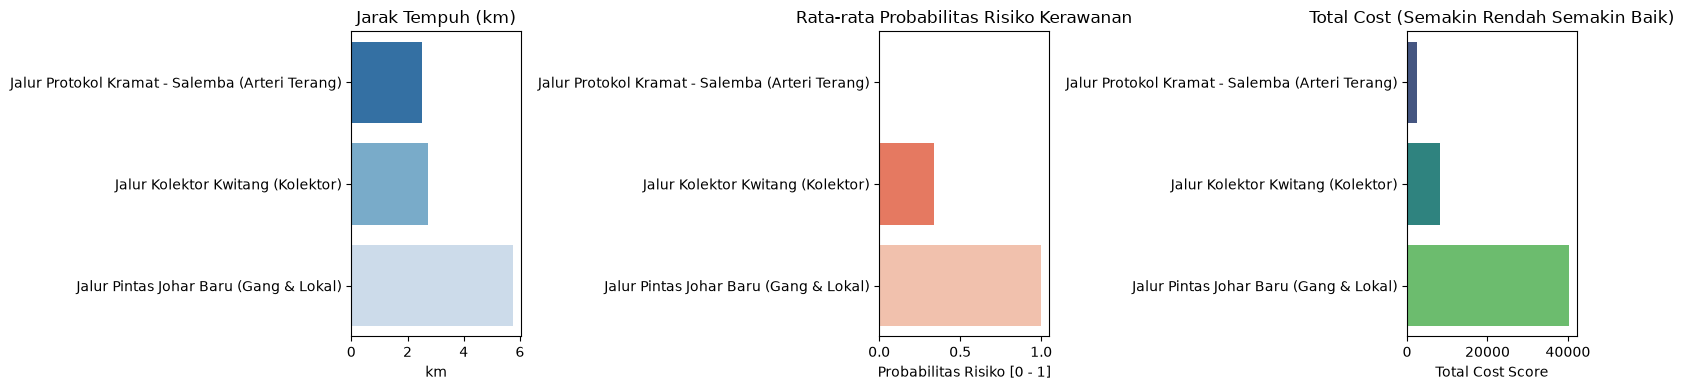

In [5]:
# Gunakan mode Sangat Aman (Alpha = 3.0) untuk visualisasi
df_final_rank, best_route_obj = score_and_rank_routes(
    candidate_routes,
    classifier_pipeline,
    alpha=3.0,
    hour=TRAVEL_HOUR,
    day_of_week=DAY_OF_WEEK,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Jarak Tempuh
sns.barplot(ax=axes[0], data=df_final_rank, x="distance_km", y="route_name", palette="Blues_r")
axes[0].set_title("Jarak Tempuh (km)")
axes[0].set_xlabel("km")
axes[0].set_ylabel("")

# 2. Rata-Rata Risiko Kerawanan
sns.barplot(ax=axes[1], data=df_final_rank, x="mean_risk_prob", y="route_name", palette="Reds_r")
axes[1].set_title("Rata-rata Probabilitas Risiko Kerawanan")
axes[1].set_xlabel("Probabilitas Risiko [0 - 1]")
axes[1].set_ylabel("")

# 3. Total Cost (Ranking Metric)
sns.barplot(ax=axes[2], data=df_final_rank, x="total_cost", y="route_name", palette="viridis")
axes[2].set_title("Total Cost (Semakin Rendah Semakin Baik)")
axes[2].set_xlabel("Total Cost Score")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

## 5. Visualisasi Peta Interaktif Rekomendasi Rute (Folium)
Menampilkan rute-rute kandidat di atas peta Jakarta lengkap dengan lapisan zona hotspot DBSCAN (Tahap 1).
- **Hijau Tebal:** Rute Rekomendasi Utama (*Safe Route*).
- **Merah / Oranye:** Rute alternatif yang memiliki titik bahaya tinggi.

In [6]:
# Inisialisasi peta berpusat di antara Senen dan Menteng
m = folium.Map(location=[-6.1850, 106.8450], zoom_start=14, tiles="CartoDB positron")

# Tambahkan marker Start dan Finish
start_coord = candidate_routes[0]["waypoints"][0]
end_coord = candidate_routes[0]["waypoints"][-1]

folium.Marker(
    location=start_coord,
    popup="<b>Titik Awal:</b> Stasiun Pasar Senen",
    icon=folium.Icon(color="blue", icon="play"),
).add_to(m)

folium.Marker(
    location=end_coord,
    popup="<b>Titik Tujuan:</b> Kawasan Menteng / Cikini",
    icon=folium.Icon(color="green", icon="stop"),
).add_to(m)

# Tambahkan lapisan lingkaran hotspot dari Tahap 1
hotspots_file = ml_root / "data" / "processed" / "cluster_hotspots_summary.csv"
if hotspots_file.exists():
    df_h = pd.read_csv(hotspots_file)
    for _, h in df_h.head(5).iterrows():
        folium.Circle(
            location=[h["centroid_lat"], h["centroid_lon"]],
            radius=float(h["radius_meters"]),
            color="#d90429", fill=True, fill_color="#d90429", fill_opacity=0.25,
            tooltip=f"Hotspot #{int(h['cluster_id'])}: {h['top_incident']} (Risk: {h['risk_score']})",
        ).add_to(m)

# Gambar setiap rute kandidat
route_colors = {
    1: "#2b9348",  # Rank 1: Hijau segar (Rekomendasi Utama)
    2: "#f77f00",  # Rank 2: Oranye
    3: "#d90429",  # Rank 3: Merah tua (Bahaya / Tidak Disarankan)
}

for _, row in df_final_rank.iterrows():
    rank = int(row["recommendation_rank"])
    color = route_colors.get(rank, "gray")
    weight = 7 if rank == 1 else 4
    opacity = 0.95 if rank == 1 else 0.70
    
    popup_text = f"""
    <b>Peringkat #{rank}:</b> {row['route_name']}<br>
    <b>Jarak:</b> {row['distance_km']} km | <b>Waktu:</b> {row['duration_min']} mnt<br>
    <b>Safety Score:</b> <span style='color:green;font-weight:bold;'>{row['safety_score']}/100</span><br>
    <b>Rata-rata Risiko:</b> {row['mean_risk_prob'] * 100:.1f}%<br>
    <b>Total Cost:</b> {row['total_cost']}
    """
    
    folium.PolyLine(
        locations=row["waypoints"],
        color=color,
        weight=weight,
        opacity=opacity,
        popup=folium.Popup(popup_text, max_width=280),
        tooltip=f"Peringkat #{rank}: {row['route_name']} ({row['distance_km']} km, Safety: {row['safety_score']})",
    ).add_to(m)

# Simpan peta interaktif sebagai HTML
report_dir = ml_root / "reports"
report_dir.mkdir(parents=True, exist_ok=True)
map_path = report_dir / "peta_rekomendasi_rute.html"
m.save(str(map_path))
print(f"Peta rute interaktif berhasil disimpan di: {map_path}")
m

Peta rute interaktif berhasil disimpan di: d:\PPTI\Cawu 4 Projects\JagaDia\ML\reports\peta_rekomendasi_rute.html


c:\Users\evanh\anaconda3\envs\JagaDia\Lib\site-packages\folium\raster_layers.py:128: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 6. Ekspor GeoJSON Rute Aman untuk Aplikasi Android (`MapActivity`)
Format yang dihasilkan adalah **GeoJSON `FeatureCollection` dengan geometri `LineString`** yang siap langsung dikonsumsi oleh fungsi `MapActivity.showRoute(geoJson)` di aplikasi Android.

In [7]:
recommended_geojson = best_route_obj["geojson"]

# Simpan ke data/processed
route_out_path = ml_root / "data" / "processed" / "recommended_safe_route.json"
with open(route_out_path, "w", encoding="utf-8") as f:
    json.dump(recommended_geojson, f, indent=2)

print(f"File GeoJSON rute aman tersimpan di: {route_out_path}")
print("\nPreview isi GeoJSON untuk Android MapLibre:")
print(json.dumps(recommended_geojson, indent=2)[:500] + "\n...")

File GeoJSON rute aman tersimpan di: d:\PPTI\Cawu 4 Projects\JagaDia\ML\data\processed\recommended_safe_route.json

Preview isi GeoJSON untuk Android MapLibre:
{
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "properties": {
        "route_id": "R02_ARTERI_SAFE",
        "route_name": "Jalur Protokol Kramat - Salemba (Arteri Terang)",
        "distance_km": 2.5,
        "duration_min": 5.6,
        "safety_score": 99.6,
        "mean_risk": 0.004,
        "alpha_used": 3.0,
        "rank": 1
      },
      "geometry": {
        "type": "LineString",
        "coordinates": [
          [
            106.8451,
        
...


## 7. Kesimpulan & Penjelasan untuk Laporan Akhir (Session 27-28)

1. **Penerapan Recommender System Berbasis Konten (Content-Based):**
   - Setiap rute dimodelkan sebagai item dengan vektor atribut (jarak, durasi, risiko rata-rata, risiko puncak).
   - Preferensi pengguna dimodelkan melalui parameter sensitivitas $\alpha$.
2. **Trade-off Cepat vs Aman:**
   - Pada $\alpha = 0.2$ (*Prefer Cepat*), sistem memilih Rute 1 (Jalur Pintas Johar Baru) karena jaraknya paling pendek (2.4 km).
   - Pada $\alpha = 3.0$ (*Sangat Aman*), sistem mendeteksi bahwa Rute 1 menembus hotspot tawuran dengan risiko puncak 90%, sehingga sistem **merekomendasikan Rute 2 (Jalur Protokol Salemba Raya)** dengan *Safety Score* 89/100 meskipun berjarak lebih panjang 500 meter.
3. **Integrasi End-to-End dengan Software Engineering:**
   - Output GeoJSON `LineString` ini siap di-return oleh endpoint FastAPI `POST /route` di `APP/backend/` dan langsung digambar di peta Android MapLibre via `MapActivity.showRoute(geoJson)`.